# Pairwise comparison: Iris sepal width

<div>
<img src="Images/iris.png" width='50%' title=""/>
</div>

To illustrate pairwise comparison between all pairs of levels of a categorical variable we'll use the Iris sepal/petal width/length dataset.

## Imports

In [20]:
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind
from itertools import combinations
from statsmodels.formula.api import ols
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests

## Load and print the data

First we read in the dataset and print it to see how it looks and what the variable names, types and values are.

In [22]:
iris = pd.read_csv('../Datasets/iris.csv')
iris

,sepal_length,sepal_width,petal_length,petal_width,Species,Site
0,5.0,2.0,3.5,1.0,versicolor,Field
1,6.0,2.2,5.0,1.5,virginica,Field
2,5.5,2.3,4.0,1.3,versicolor,Field
3,5.0,2.3,3.3,1.0,versicolor,Field
4,5.5,2.4,3.8,1.1,versicolor,Field
...,...,...,...,...,...,...
145,5.1,3.8,1.5,0.3,setosa,Roadside
146,5.1,3.8,1.9,0.4,setosa,Roadside
147,7.9,3.8,6.4,2.0,virginica,Roadside
148,5.8,4.0,1.2,0.2,setosa,Roadside


There are six variables. The first four, "sepal_length", "sepal_width", "petal_length" and "petal_width", are continuous numerical. The last two, "Species" and "Site" are categorical. We're not interested in "Site" in this analysis.

The code below prints out the levels (the unique values) of "Species".

In [24]:
print(iris['Species'].unique())

['versicolor' 'virginica' 'setosa']


There are three species: versicolor, virginica and setosa. 

In this notebook we're only examining the relationship between sepal width and species. In a more thorough analysis the other sepal and petal measurements would be used.

The response variable is `sepal_width` and the explanatory variables is `Species`.

## Plot and interpret the data

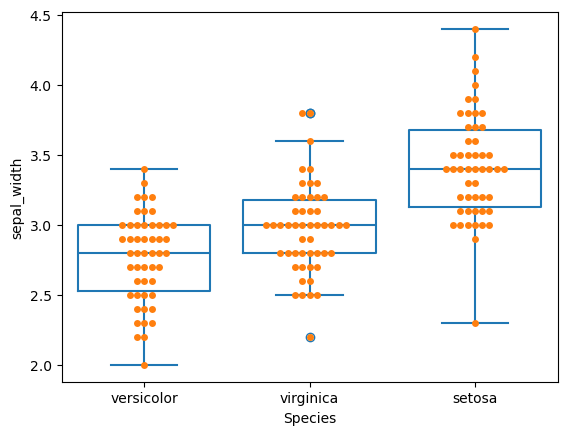

In [27]:
sns.boxplot(data=iris, x='Species', y='sepal_width', fill=None);
sns.swarmplot(data=iris, x='Species', y='sepal_width');


It looks as if setosa has wider mean sepal width than versicolor and virginica. But it's perhaps not clear if mean sepal width differs between versicolor and virginica.

## ANOVA to test null hypothesis that all means are the same

First we must perform an ANOVA "omnibus" test to determine the compatibility of the data with the null hypothesis that the mean sepal widths of all species are the same. 

You can use either `anova_oneway` or a linear model, they will both give the same answer.

In [31]:
# ANOVA using anova_oneway

test = anova_oneway(iris['sepal_width'], iris['Species'], use_var='equal')

print(f'degrees of freedom = {test.df}')
print(f'F-statistic = {test.statistic:.3g}')
print(f'P = {test.pvalue:.2g}')

degrees of freedom = (2.0, 147.0)
F-statistic = 47.4
P = 1.3e-16


In [32]:
# ANOVA using a linear model

formula = 'sepal_width ~ Species'
fit = ols(formula, iris).fit()
fit.summary().tables[0]

Dep. Variable:,sepal_width,R-squared:,0.392
Model:,OLS,Adj. R-squared:,0.384
Method:,Least Squares,F-statistic:,47.36
Date:,"Thu, 29 Oct 2026",Prob (F-statistic):,1.33e-16
Time:,19:57:43,Log-Likelihood:,-49.688
No. Observations:,150,AIC:,105.4
Df Residuals:,147,BIC:,114.4
Df Model:,2,,
Covariance Type:,nonrobust,,


With *P* = 1 x 10<sup>-16</sup> the data are incompatible with the null hypothesis. We can continue with the analysis.

## All pairwise comparisons

The following code loops through all three pairwise comparisons, performs a *t*-test for each and saves the results in a DataFrame.

In [35]:
# set up a dictionary to save the results of all pairwise comparisons
results = {'comparison':[], 'p_raw':[]}

# group the sepal widths into species
groups = iris.groupby('Species')['sepal_width']

# loop through all pairwise comparisons
for (species1, widths1), (species2, widths2) in combinations(groups, 2):
    # save the names of the two species being compared
    results['comparison'].append((species1, species2))

    # save the raw p value of the t-test
    test = ttest_ind(widths1, widths2)
    results['p_raw'].append(test.pvalue)

# convert the results into a DataFrame for ease of analysis
results_df = pd.DataFrame(results)
results_df

,comparison,p_raw
0,"(setosa, versicolor)",4.362239e-15
1,"(setosa, virginica)",8.916634e-09
2,"(versicolor, virginica)",1.819100e-03


## Adjust raw *P*-values using Holm's method

In [37]:
# send the raw p-values for adjustment using the Holm method
# and save the adjusted p-values into a new column in the dataframe called p_adj
results_df['p_adj'] = multipletests(results_df['p_raw'], method='holm')[1]

# print the dataframe of raw and adjusted p-values sorted on ascending adjusted p-value
results_df.sort_values('p_adj')

,comparison,p_raw,p_adj
0,"(setosa, versicolor)",4.362239e-15,1.308672e-14
1,"(setosa, virginica)",8.916634e-09,1.783327e-08
2,"(versicolor, virginica)",1.819100e-03,1.819100e-03


All pairwise *P*-values are less than 0.05. So the sepal width of each species is significantly different from the other two.

## Estimated sepal widths

The default of a linear model is to estimate the mean of the reference level and then compare everything else to that reference. For example the model `sepal_width ~ Species` will estimate the mean sepal width of setosa (the first alphabetically) then estimate the differences between setosa and versicolor and setosa and virginica. 

But here we would like the estimates of sepal width of each species separately without having a specific reference. There is a quick and easy way to do this by including `-1` in the formula of the linear model like so:

`sepal_width ~ Species -1`

`-1` does not mean "subtract one", it means remove the `Intercept` coefficient from the model. This prevents the algorithm from estimating differences relative to the reference.

In [40]:
# Sepal width estimates of each species

formula = 'sepal_width ~ Species -1'
fit = ols(formula, iris).fit()
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Species[setosa],3.4180,0.048,70.998,0.000,3.323,3.513
Species[versicolor],2.7700,0.048,57.538,0.000,2.675,2.865
Species[virginica],2.9740,0.048,61.775,0.000,2.879,3.069


## Report the outcome

Mean sepal widths of iris species are 3.42 ± 0.05 mm (mean ± SEM) for setosa, 2.77 ± 0.05 mm for versicolor and 2.97 ± 0.05 mm for virginica. All pairwise *t*-tests, adjusted for multiple comparison using the Holm method, show that mean sepal width for each species is significantly different from the others.